# 03 — Modelo preditivo de NPS (desafio opcional)

**Pergunta que o modelo responde:**
> *"Com base no que já sabemos sobre o pedido, a entrega e o atendimento, qual nota este cliente provavelmente vai dar, e qual o risco de ele virar detrator, **antes** de a pesquisa ser enviada?"*

## 1. Estratégia: regressão ou classificação?

Usamos **as duas abordagens**, porque elas respondem a necessidades diferentes do negócio:

| Abordagem | O que prevê | Para que serve no negócio |
|---|---|---|
| **Regressão** (modelo principal) | A **nota** de 0 a 10 | Acompanhar o "NPS previsto" da operação, simular cenários ("e se reduzirmos 1 dia de atraso?") e entender **quanto** cada fator tira da nota. |
| **Classificação** | A **probabilidade** de o cliente ser **detrator** | Criar uma **lista de prioridade** diária para o time de atendimento agir de forma proativa. |

**Justificativa técnica:** a nota é contínua (tem casas decimais), então a regressão aproveita toda a informação. Já a classificação conversa diretamente com a regra do NPS (detrator = nota < 7) e gera uma probabilidade que pode ser usada para ordenar a fila de atendimento.

**Justificativa de negócio:** o gestor quer saber **onde agir** (regressão explica o peso de cada fator) e **com quem agir primeiro** (classificação ordena os clientes por risco).

In [1]:
# Configuração: permite importar o pacote "src" a partir da pasta notebooks/
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor, RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, classification_report, mean_absolute_error, r2_score,
    roc_auc_score, root_mean_squared_error,
)
from sklearn.model_selection import KFold, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src import config
from src.data_preparation import load_processed_data, classify_nps, calculate_nps
from src.visualization import set_plot_style, save_figure

set_plot_style()
df = load_processed_data()
print(f"{len(df):,} pedidos carregados")

2,500 pedidos carregados


## 2. Definição da variável alvo

- **Regressão:** `nps_score` (nota de 0 a 10).
- **Classificação:** `is_detractor` = 1 se a nota for menor que 7 (regra oficial do NPS), 0 caso contrário.

## 3. Seleção e preparação das variáveis de entrada

**Regra de ouro:** só entra no modelo o que a empresa **já sabe antes de enviar a pesquisa**.

| Grupo | Variáveis usadas | Disponível antes da pesquisa? |
|---|---|---|
| Cliente | idade, região, tempo de relacionamento | ✅ cadastro |
| Pedido | valor, itens, desconto, parcelas | ✅ checkout |
| Logística | tempo de entrega, atraso, frete, tentativas | ✅ rastreio |
| Atendimento | contatos com SAC, tempo de resolução, reclamações | ✅ CRM/SAC durante a jornada |

**Variáveis excluídas:**
- `customer_id`, `order_id`: são identificadores, não têm significado preditivo.
- `csat_internal_score`, `repeat_purchase_30d`: são coletadas **depois** ou **junto** da pesquisa → **vazamento de dados** (ver seção 8).
- Faixas criadas na EDA (`delay_bucket`, `age_group` etc.): são versões agrupadas de variáveis que já estão no modelo, então seriam redundantes.

> **Premissa:** assumimos que `complaints_count` registra reclamações feitas **durante** a jornada (antes da pesquisa). Se a empresa só registrar reclamações depois da pesquisa, essa variável deve sair do modelo.

**Preparação (dentro de um `Pipeline`, para evitar vazamento entre treino e teste):**
- variáveis numéricas → padronização (`StandardScaler`), para que fiquem na mesma escala;
- região → *one-hot encoding* (uma coluna 0/1 para cada região).

In [2]:
NUMERIC_FEATURES = [
    "customer_age", "customer_tenure_months",
    "order_value", "items_quantity", "discount_value", "payment_installments",
    "delivery_time_days", "delivery_delay_days", "freight_value", "delivery_attempts",
    "customer_service_contacts", "resolution_time_days", "complaints_count",
]
CATEGORICAL_FEATURES = ["customer_region"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X = df[FEATURES]
y_score = df[config.TARGET_SCORE]
y_detractor = df[config.TARGET_DETRACTOR]


def build_preprocessor() -> ColumnTransformer:
    """Padroniza as numéricas e transforma a região em colunas 0/1."""
    return ColumnTransformer([
        ("numeric", StandardScaler(), NUMERIC_FEATURES),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ])


print(f"{len(FEATURES)} variáveis de entrada:", FEATURES)

14 variáveis de entrada: ['customer_age', 'customer_tenure_months', 'order_value', 'items_quantity', 'discount_value', 'payment_installments', 'delivery_time_days', 'delivery_delay_days', 'freight_value', 'delivery_attempts', 'customer_service_contacts', 'resolution_time_days', 'complaints_count', 'customer_region']


## 4. Separação dos dados

- **80% treino / 20% teste**, com `random_state=42` para reprodutibilidade.
- A separação é **estratificada pela categoria do NPS**, para que treino e teste tenham a mesma proporção de detratores, neutros e promotores (os promotores são só 4%, então sem estratificação poderiam ficar mal representados).
- A escolha do modelo é feita com **validação cruzada de 5 partes, apenas no treino**. O conjunto de teste é usado **uma única vez**, no final, para medir o desempenho em dados "nunca vistos".

In [3]:
X_train, X_test, y_score_train, y_score_test, y_det_train, y_det_test = train_test_split(
    X, y_score, y_detractor,
    test_size=0.2,
    random_state=config.RANDOM_STATE,
    stratify=df[config.NPS_CATEGORY],
)
print(f"Treino: {len(X_train):,} pedidos | Teste: {len(X_test):,} pedidos")
print(f"% detratores -> treino: {y_det_train.mean():.1%} | teste: {y_det_test.mean():.1%}")

Treino: 2,000 pedidos | Teste: 500 pedidos
% detratores -> treino: 84.4% | teste: 84.4%


## 5. Modelo de regressão: prever a nota

Comparamos 4 modelos, do mais simples ao mais complexo:

1. **Baseline (média):** sempre "chuta" a nota média. Qualquer modelo útil precisa ser melhor que ele.
2. **Regressão Linear:** simples e **fácil de explicar** ("cada dia de atraso tira X pontos").
3. **Random Forest:** conjunto de árvores de decisão, capta relações não lineares.
4. **Gradient Boosting:** árvores construídas em sequência, normalmente o mais forte em dados tabulares.

**Métricas:**
- **MAE** (erro médio absoluto): "em média, o modelo erra a nota em X pontos". É a métrica mais fácil de explicar ao negócio.
- **RMSE:** parecida com o MAE, mas pune mais os erros grandes.
- **R²:** quanto da variação da nota o modelo consegue explicar (0 = nada, 1 = tudo).

In [4]:
regression_candidates = {
    "Baseline (média)": DummyRegressor(strategy="mean"),
    "Regressão Linear": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=config.RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(max_depth=4, learning_rate=0.05, random_state=config.RANDOM_STATE),
}
cv_regression = KFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)

regression_results = []
for model_name, estimator in regression_candidates.items():
    pipeline = Pipeline([("preprocess", build_preprocessor()), ("model", estimator)])
    scores = cross_validate(
        pipeline, X_train, y_score_train, cv=cv_regression,
        scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"],
    )
    regression_results.append({
        "modelo": model_name,
        "MAE": -scores["test_neg_mean_absolute_error"].mean(),
        "RMSE": -scores["test_neg_root_mean_squared_error"].mean(),
        "R²": scores["test_r2"].mean(),
    })

regression_results = pd.DataFrame(regression_results).set_index("modelo").round(3)
regression_results

,MAE,RMSE,R²
modelo,,,
Baseline (média),2.039,2.500,-0.001
Regressão Linear,1.309,1.648,0.565
Random Forest,1.355,1.696,0.540
Gradient Boosting,1.328,1.664,0.557


**Escolha do modelo:** a **Regressão Linear** teve o melhor desempenho na validação cruzada (menor erro e maior R²), ligeiramente à frente dos modelos de árvore.
Isso indica que a relação entre os fatores e a nota é **aproximadamente linear** (cada dia de atraso tira mais ou menos a mesma quantidade de pontos).
Como, além de mais precisa, ela é **muito mais fácil de explicar** para o negócio, é o modelo escolhido.

### 5.1 Avaliação final no conjunto de teste

In [5]:
regression_model = Pipeline([("preprocess", build_preprocessor()), ("model", LinearRegression())])
regression_model.fit(X_train, y_score_train)

# Limitamos a previsão à escala 0-10 (a regressão linear pode passar um pouco dos limites)
y_score_pred = np.clip(regression_model.predict(X_test), 0, 10)

baseline_mae = mean_absolute_error(y_score_test, np.full(len(y_score_test), y_score_train.mean()))
test_mae = mean_absolute_error(y_score_test, y_score_pred)
print(f"MAE  (teste): {test_mae:.2f} pontos  | baseline: {baseline_mae:.2f} pontos")
print(f"RMSE (teste): {root_mean_squared_error(y_score_test, y_score_pred):.2f}")
print(f"R²   (teste): {r2_score(y_score_test, y_score_pred):.2f}")
print(f"\nO modelo erra {(1 - test_mae / baseline_mae):.0%} menos que o 'chute' pela média.")

MAE  (teste): 1.39 pontos  | baseline: 2.11 pontos
RMSE (teste): 1.78
R²   (teste): 0.51

O modelo erra 34% menos que o 'chute' pela média.


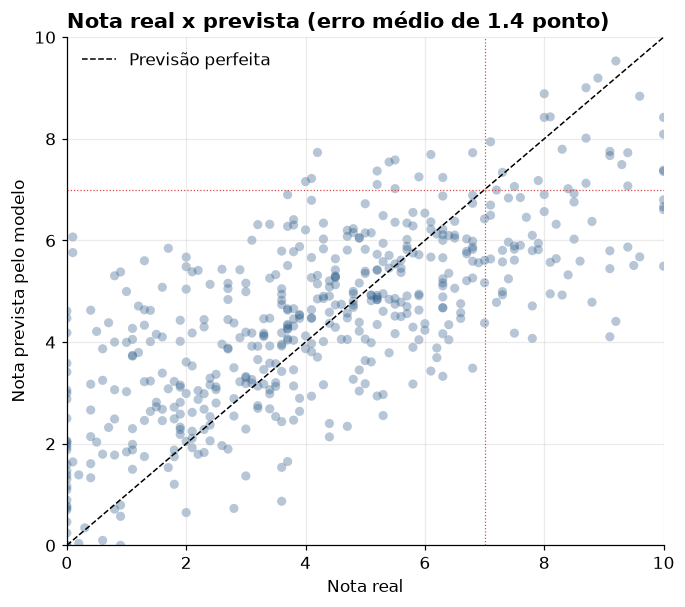

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_score_test, y_score_pred, alpha=0.35, color=config.COLOR_PRIMARY, edgecolor="none")
ax.plot([0, 10], [0, 10], color="black", linestyle="--", linewidth=1, label="Previsão perfeita")
ax.axvline(7, color=config.COLOR_DETRACTOR, linewidth=0.8, linestyle=":")
ax.axhline(7, color=config.COLOR_DETRACTOR, linewidth=0.8, linestyle=":")
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_xlabel("Nota real")
ax.set_ylabel("Nota prevista pelo modelo")
ax.set_title(f"Nota real x prevista (erro médio de {test_mae:.1f} ponto)")
ax.legend(frameon=False, loc="upper left")
save_figure(fig, "fig10_modelo_real_vs_previsto.png")
plt.show()

In [7]:
# Mesmo prevendo a nota, conseguimos acertar a CATEGORIA do NPS?
real_category = classify_nps(y_score_test.reset_index(drop=True))
predicted_category = classify_nps(pd.Series(y_score_pred))
category_accuracy = (real_category == predicted_category).mean()

print(f"Acerto da categoria (detrator/neutro/promotor): {category_accuracy:.0%}")
print(f"Nota média real    : {y_score_test.mean():.2f}")
print(f"Nota média prevista: {y_score_pred.mean():.2f}")
print(f"NPS real do conjunto de teste    : {calculate_nps(y_score_test):+.0f}")
print(f"NPS calculado com notas previstas: {calculate_nps(pd.Series(y_score_pred)):+.0f}")
pd.crosstab(real_category, predicted_category, rownames=["Real"], colnames=["Previsto"])

Acerto da categoria (detrator/neutro/promotor): 84%
Nota média real    : 4.24
Nota média prevista: 4.46
NPS real do conjunto de teste    : -80
NPS calculado com notas previstas: -92


Previsto,Detrator,Neutro,Promotor
Real,,,
Detrator,410,12,0
Neutro,43,11,2
Promotor,11,10,1


**Leitura (com honestidade):**
- O modelo erra a nota, em média, em cerca de **1,4 ponto**, e chega perto da **nota média** do grupo (4,5 prevista contra 4,2 real no teste). Isso permite acompanhar uma **"nota média prevista"** diária da operação, sem esperar a pesquisa.
- Porém, como todo modelo de regressão, ele "puxa" as notas extremas para o meio. Por isso, quase não prevê promotores e o **NPS calculado a partir das notas previstas fica mais negativo que o real**. O acerto de categoria (84%) é parecido com o de simplesmente dizer que todos são detratores.
- **Conclusão prática:** use a regressão para **acompanhar a nota média e simular cenários**, e não para classificar cada cliente. Para priorizar clientes individualmente, usamos o modelo de classificação abaixo.

## 6. Modelo de classificação: risco de virar detrator

Como 84% da base é detratora, a **acurácia engana** (um modelo que diz "todo mundo é detrator" acerta 84%). Por isso usamos:

- **ROC-AUC:** capacidade de **ordenar** clientes do maior para o menor risco (0,5 = sorteio, 1,0 = perfeito). É a métrica principal, porque o uso prático é uma **fila de prioridade**.
- **Recall:** dos detratores reais, quantos o modelo encontrou.
- **Precisão:** dos que o modelo apontou como detratores, quantos realmente eram.

Usamos `class_weight="balanced"` para que o modelo dê atenção também à classe menor (não detratores).

In [8]:
classification_candidates = {
    "Baseline (classe mais comum)": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            random_state=config.RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, class_weight="balanced",
                                                        random_state=config.RANDOM_STATE),
}
cv_classification = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)

classification_results = []
for model_name, estimator in classification_candidates.items():
    pipeline = Pipeline([("preprocess", build_preprocessor()), ("model", estimator)])
    scores = cross_validate(pipeline, X_train, y_det_train, cv=cv_classification,
                            scoring=["roc_auc", "recall", "precision", "f1"])
    classification_results.append({
        "modelo": model_name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "Recall": scores["test_recall"].mean(),
        "Precisão": scores["test_precision"].mean(),
        "F1": scores["test_f1"].mean(),
    })

classification_results = pd.DataFrame(classification_results).set_index("modelo").round(3)
classification_results

,ROC-AUC,Recall,Precisão,F1
modelo,,,,
Baseline (classe mais comum),0.500,1.000,0.843,0.915
Regressão Logística,0.896,0.808,0.959,0.877
Random Forest,0.887,0.861,0.946,0.901
Gradient Boosting,0.890,0.833,0.953,0.889


**Escolha do modelo:** a **Regressão Logística** teve o maior ROC-AUC (por pequena margem), ou seja, é a melhor para **ordenar clientes por risco**. Ela também é interpretável e consistente com o modelo de regressão (ambos lineares).

### 6.1 Avaliação final no conjunto de teste

In [9]:
classification_model = Pipeline([
    ("preprocess", build_preprocessor()),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced")),
])
classification_model.fit(X_train, y_det_train)

detractor_probability = classification_model.predict_proba(X_test)[:, 1]
y_det_pred = classification_model.predict(X_test)

print(f"ROC-AUC (teste): {roc_auc_score(y_det_test, detractor_probability):.3f}\n")
print(classification_report(y_det_test, y_det_pred, target_names=["Não detrator", "Detrator"], digits=2))

ROC-AUC (teste): 0.871

              precision    recall  f1-score   support

Não detrator       0.42      0.78      0.55        78
    Detrator       0.95      0.80      0.87       422

    accuracy                           0.80       500
   macro avg       0.69      0.79      0.71       500
weighted avg       0.87      0.80      0.82       500



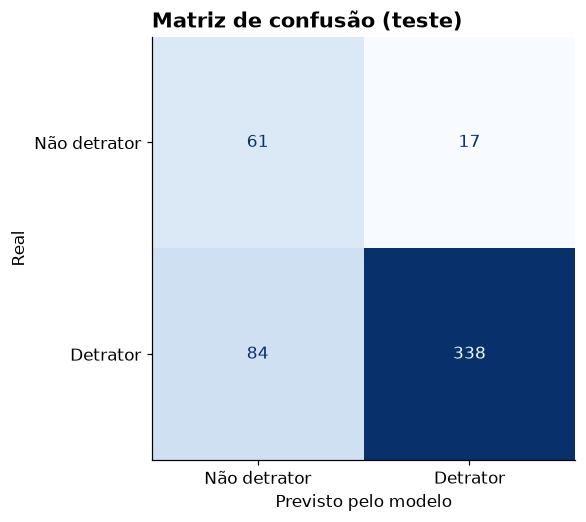

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_det_test, y_det_pred, display_labels=["Não detrator", "Detrator"],
    cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title("Matriz de confusão (teste)")
ax.set_xlabel("Previsto pelo modelo")
ax.set_ylabel("Real")
ax.grid(False)
save_figure(fig, "fig11_matriz_confusao.png")
plt.show()

In [11]:
# Uso como fila de prioridade: se o time só consegue contatar 20% dos clientes,
# quantos dos clientes com nota mais baixa (0 a 3) estão nesse grupo?
test_ranking = pd.DataFrame({"nota_real": y_score_test.values, "prob_detrator": detractor_probability})
test_ranking = test_ranking.sort_values("prob_detrator", ascending=False).reset_index(drop=True)
top_20_pct = test_ranking.head(int(len(test_ranking) * 0.2))

very_unhappy = test_ranking["nota_real"] < 3
captured = (top_20_pct["nota_real"] < 3).sum() / very_unhappy.sum()
print(f"Nota média dos 20% com MAIOR risco previsto: {top_20_pct['nota_real'].mean():.1f}")
print(f"Nota média dos 20% com MENOR risco previsto: {test_ranking.tail(len(top_20_pct))['nota_real'].mean():.1f}")
print(f"Os 20% de maior risco concentram {captured:.0%} dos clientes muito insatisfeitos (nota < 3).")

Nota média dos 20% com MAIOR risco previsto: 1.6
Nota média dos 20% com MENOR risco previsto: 6.6
Os 20% de maior risco concentram 51% dos clientes muito insatisfeitos (nota < 3).


**Leitura:** o modelo separa muito bem os clientes. Os 20% que ele aponta como **maior risco** têm notas muito mais baixas que os 20% de **menor risco**, e concentram uma parte grande dos clientes mais insatisfeitos.
Ou seja, **se o time de atendimento só tiver capacidade para ligar para 1 em cada 5 clientes, o modelo diz para quem ligar primeiro.**

## 7. O que mais pesa na nota? (interpretação do modelo)

Para explicar o modelo ao negócio, treinamos a regressão linear com as variáveis **na escala original** (sem padronizar).
Assim, cada coeficiente se lê como: **"cada unidade a mais desta variável muda a nota em X pontos"**.

In [12]:
# Mesmo modelo linear, mas sem padronização, para leitura direta em "pontos de nota"
interpretable_model = LinearRegression().fit(X_train[NUMERIC_FEATURES], y_score_train)
impact_per_unit = pd.Series(interpretable_model.coef_, index=NUMERIC_FEATURES).round(3)

readable_names = {
    "delivery_delay_days": "+1 dia de atraso",
    "complaints_count": "+1 reclamação",
    "customer_service_contacts": "+1 contato com o SAC",
    "resolution_time_days": "+1 dia para resolver",
    "delivery_attempts": "+1 tentativa de entrega",
    "items_quantity": "+1 item no pedido",
    "payment_installments": "+1 parcela",
    "freight_value": "+R$ 1 de frete",
    "customer_tenure_months": "+1 mês de relacionamento",
    "customer_age": "+1 ano de idade",
    "order_value": "+R$ 1 no pedido",
    "discount_value": "+R$ 1 de desconto",
    "delivery_time_days": "+1 dia no prazo total",
}
impact_table = impact_per_unit.rename(index=readable_names).sort_values().to_frame("impacto_na_nota")
impact_table

,impacto_na_nota
+1 dia de atraso,-0.937
+1 reclamação,-0.373
+1 contato com o SAC,-0.354
+1 dia para resolver,-0.140
+R$ 1 de frete,-0.007
+1 dia no prazo total,-0.002
+1 mês de relacionamento,-0.001
+R$ 1 de desconto,-0.001
+1 ano de idade,0.001
+R$ 1 no pedido,0.001


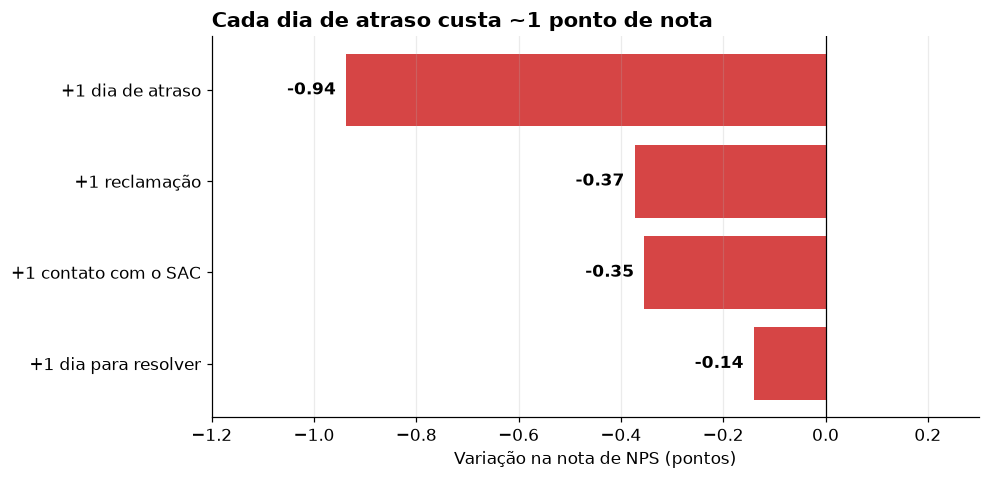

In [13]:
# Gráfico só com os fatores relevantes (|impacto| >= 0,12 ponto por unidade)
relevant_impact = impact_table[impact_table["impacto_na_nota"].abs() >= 0.12].sort_values("impacto_na_nota", ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = [config.COLOR_DETRACTOR if v < 0 else config.COLOR_PROMOTER for v in relevant_impact["impacto_na_nota"]]
ax.barh(relevant_impact.index, relevant_impact["impacto_na_nota"], color=colors)
for y, value in enumerate(relevant_impact["impacto_na_nota"]):
    ax.text(value - 0.02 if value < 0 else value + 0.02, y, f"{value:+.2f}", va="center",
            ha="right" if value < 0 else "left", fontweight="bold")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-1.2, 0.3)
ax.set_xlabel("Variação na nota de NPS (pontos)")
ax.set_title("Cada dia de atraso custa ~1 ponto de nota")
ax.grid(axis="y", visible=False)
save_figure(fig, "fig12_impacto_por_fator.png")
plt.show()

In [14]:
# Importância por permutação: quanto o erro do modelo PIORA se "embaralharmos" cada variável.
# É uma forma de medir importância que não depende da escala das variáveis.
permutation = permutation_importance(
    regression_model, X_test, y_score_test, n_repeats=20,
    random_state=config.RANDOM_STATE, scoring="neg_mean_absolute_error",
)
permutation_table = (
    pd.DataFrame({"variavel": FEATURES, "aumento_do_erro_MAE": permutation.importances_mean})
    .sort_values("aumento_do_erro_MAE", ascending=False)
    .round(3)
    .reset_index(drop=True)
)
permutation_table

,variavel,aumento_do_erro_MAE
0,delivery_delay_days,0.805
1,complaints_count,0.177
2,resolution_time_days,0.126
3,customer_service_contacts,0.061
4,customer_region,0.004
5,delivery_attempts,0.003
6,customer_tenure_months,0.001
7,payment_installments,0.000
8,discount_value,0.000
9,items_quantity,0.000


**Em linguagem de gestão:**
- **+1 dia de atraso ≈ -1 ponto na nota.** É, disparado, a alavanca mais forte.
- **+1 reclamação ≈ -0,4 ponto** e **+1 contato com o SAC ≈ -0,3 ponto.**
- **+1 dia para resolver um problema ≈ -0,15 ponto.**
- Idade, região, valor do pedido, desconto e parcelas têm impacto **praticamente zero**.
- "Tentativas de entrega" aparece com um efeito pequeno e positivo (+0,1), sem explicação de negócio clara e com importância nula na permutação. Tratamos como **ruído** e não a usamos para recomendações.

As duas formas de medir (coeficientes e permutação) apontam as **mesmas 4 variáveis principais** da EDA (atraso, reclamações, tempo de resolução e contatos com SAC), com o **atraso disparado em 1º lugar**. Isso dá segurança na conclusão.

## 8. Teste de vazamento de dados (por que não usamos CSAT e recompra)

Para mostrar o risco, treinamos o mesmo modelo **incluindo** `csat_internal_score` e `repeat_purchase_30d`:

In [15]:
leaky_features = FEATURES + config.POST_SURVEY_COLUMNS
leaky_preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC_FEATURES + config.POST_SURVEY_COLUMNS),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
])
leaky_model = Pipeline([("preprocess", leaky_preprocessor), ("model", LinearRegression())])
leaky_scores = cross_validate(leaky_model, df.loc[X_train.index, leaky_features], y_score_train,
                              cv=cv_regression, scoring=["neg_mean_absolute_error", "r2"])

print(f"R² SEM vazamento (modelo correto): {regression_results.loc['Regressão Linear', 'R²']:.2f}")
print(f"R² COM vazamento                 : {leaky_scores['test_r2'].mean():.2f}")

R² SEM vazamento (modelo correto): 0.56
R² COM vazamento                 : 0.65


**Leitura:** o modelo "com vazamento" parece melhor no papel, mas é uma **ilusão**. Na vida real, no momento em que queremos prever a nota, **a recompra ainda não aconteceu e o CSAT ainda não foi respondido**. Um modelo assim funcionaria bem no notebook e falharia em produção.

## 9. Simulação: quanto o NPS melhoraria reduzindo atrasos?

Usamos o modelo para simular dois cenários operacionais, mantendo todo o resto igual:

In [16]:
def simulate_average_score(data: pd.DataFrame) -> float:
    """Retorna a nota média prevista pelo modelo para um cenário."""
    return float(np.clip(regression_model.predict(data[FEATURES]), 0, 10).mean())

scenarios = {
    "Hoje (cenário atual)": df.copy(),
    "Reduzir 1 dia de atraso em todos os pedidos atrasados": df.assign(
        delivery_delay_days=(df["delivery_delay_days"] - 1).clip(lower=0)),
    "Limitar o atraso a no máximo 1 dia": df.assign(
        delivery_delay_days=df["delivery_delay_days"].clip(upper=1)),
    "Limitar atraso a 1 dia + resolver no 1º contato (máx. 1 contato)": df.assign(
        delivery_delay_days=df["delivery_delay_days"].clip(upper=1),
        customer_service_contacts=df["customer_service_contacts"].clip(upper=1)),
}

simulation = pd.DataFrame(
    {"nota_media_prevista": [simulate_average_score(data) for data in scenarios.values()]},
    index=scenarios.keys(),
)
simulation["ganho_vs_hoje"] = simulation["nota_media_prevista"] - simulation["nota_media_prevista"].iloc[0]
simulation.round(2)

,nota_media_prevista,ganho_vs_hoje
Hoje (cenário atual),4.43,0.00
Reduzir 1 dia de atraso em todos os pedidos atrasados,5.26,0.83
Limitar o atraso a no máximo 1 dia,5.64,1.21
Limitar atraso a 1 dia + resolver no 1º contato (máx. 1 contato),5.90,1.47


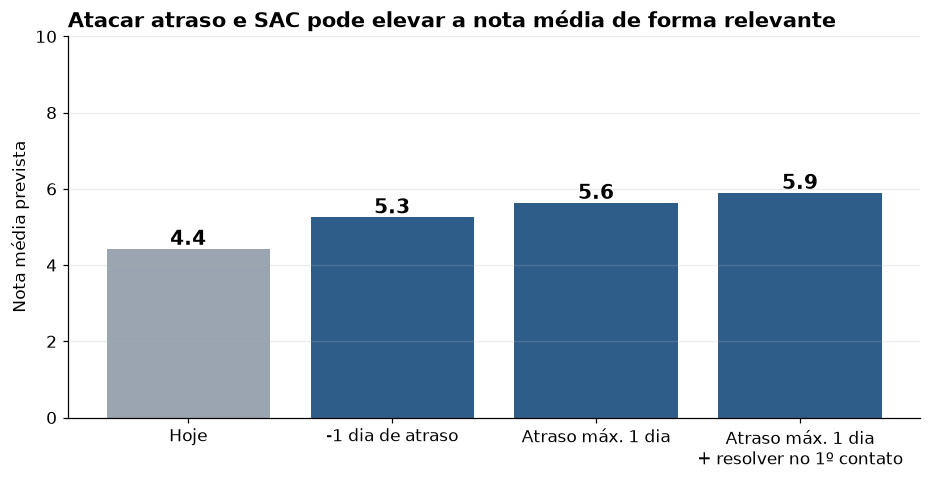

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.5))
labels = ["Hoje", "-1 dia de atraso", "Atraso máx. 1 dia", "Atraso máx. 1 dia\n+ resolver no 1º contato"]
colors = [config.COLOR_MUTED] + [config.COLOR_PRIMARY] * 3
bars = ax.bar(labels, simulation["nota_media_prevista"], color=colors)
for bar, value in zip(bars, simulation["nota_media_prevista"]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.1, f"{value:.1f}", ha="center", fontweight="bold", fontsize=13)
ax.set_ylim(0, 10)
ax.set_ylabel("Nota média prevista")
ax.set_title("Atacar atraso e SAC pode elevar a nota média de forma relevante")
ax.grid(axis="x", visible=False)
save_figure(fig, "fig13_simulacao_cenarios.png")
plt.show()

**Leitura:**
- Só **reduzir 1 dia de atraso** nos pedidos atrasados já elevaria a nota média em quase 1 ponto (**+0,8**).
- **Limitar o atraso a no máximo 1 dia** elevaria em cerca de **+1,2 ponto**.
- Somando isso a **resolver no primeiro contato com o SAC**, o ganho chega a cerca de **+1,5 ponto** (de 4,4 para 5,9).

Usamos a nota média (e não o NPS) na simulação porque, como vimos na seção 5.1, o modelo de regressão acerta bem a média, mas não a quantidade de promotores.

> ⚠️ **Cuidado:** o modelo mostra **associação**, não garante **causa e efeito**. A simulação é uma estimativa para **priorizar** ações. O ideal é validar com um teste controlado (ex.: aplicar a melhoria em uma região e comparar com outra).

## 10. Como a empresa usaria isso na prática

**Fluxo proposto (diário):**
1. Todo dia, os pedidos entregues (ou com entrega prevista) recebem um **score de risco** e uma **nota prevista**.
2. Pedidos com **alto risco** entram numa **fila de ação proativa**, antes de a pesquisa ser enviada.
3. A ação depende do motivo do risco (regras simples, abaixo).
4. Um **painel de "NPS previsto"** por região, transportadora e período permite agir antes do resultado oficial da pesquisa.

In [18]:
def score_orders(orders: pd.DataFrame) -> pd.DataFrame:
    """
    Aplica os dois modelos a novos pedidos e sugere uma ação.
    Entrada: DataFrame com as mesmas colunas de FEATURES (+ order_id).
    """
    scored = orders[["order_id"] + FEATURES].copy()
    scored["nota_prevista"] = np.clip(regression_model.predict(orders[FEATURES]), 0, 10).round(1)
    scored["prob_detrator"] = classification_model.predict_proba(orders[FEATURES])[:, 1].round(3)

    # Regras de negócio para sugerir a ação (derivadas da EDA)
    conditions = [
        orders["delivery_delay_days"] >= 2,
        orders["complaints_count"] >= 4,
        orders["customer_service_contacts"] >= 2,
    ]
    actions = [
        "Logística: contato proativo + nova data garantida + compensação",
        "Atendimento: atendimento prioritário (N2) e acompanhamento até resolver",
        "Atendimento: resolver no próximo contato, sem transferências",
    ]
    scored["acao_sugerida"] = np.select(conditions, actions, default="Monitorar")
    return scored.sort_values("prob_detrator", ascending=False)


priority_list = score_orders(df.loc[X_test.index])
priority_list[["order_id", "delivery_delay_days", "complaints_count", "customer_service_contacts",
               "nota_prevista", "prob_detrator", "acao_sugerida"]].head(10)

,order_id,delivery_delay_days,complaints_count,customer_service_contacts,nota_prevista,prob_detrator,acao_sugerida
2137,52138,7,5,1,0.0,1.000,Logística: contato proativo + nova data garant...
461,50462,5,10,6,0.0,1.000,Logística: contato proativo + nova data garant...
2353,52354,3,8,4,0.6,0.999,Logística: contato proativo + nova data garant...
2050,52051,6,5,2,0.0,0.999,Logística: contato proativo + nova data garant...
2072,52073,5,6,4,0.1,0.999,Logística: contato proativo + nova data garant...
2034,52035,6,6,3,0.0,0.999,Logística: contato proativo + nova data garant...
1931,51932,7,4,1,0.3,0.999,Logística: contato proativo + nova data garant...
168,50169,2,10,4,0.9,0.999,Logística: contato proativo + nova data garant...
1993,51994,4,6,3,0.7,0.998,Logística: contato proativo + nova data garant...
750,50751,6,4,1,0.6,0.998,Logística: contato proativo + nova data garant...


## 11. Salvando os modelos treinados

In [19]:
config.MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(regression_model, config.MODELS_DIR / "modelo_regressao_nota_nps.joblib")
joblib.dump(classification_model, config.MODELS_DIR / "modelo_classificacao_detrator.joblib")
print("Modelos salvos em:", config.MODELS_DIR.relative_to(config.PROJECT_ROOT))

# Exemplo de como recarregar e usar:
loaded_model = joblib.load(config.MODELS_DIR / "modelo_regressao_nota_nps.joblib")
print("Nota prevista para o 1º pedido do teste:", round(float(loaded_model.predict(X_test.head(1))[0]), 1))

Modelos salvos em: models
Nota prevista para o 1º pedido do teste: 5.8


## 12. Conclusões e limitações

**Conclusões**
- Um modelo **simples e explicável** (regressão linear) prevê a nota com erro médio de ~1,3 a 1,4 ponto e explica cerca de **metade** da variação da nota (R² entre 0,51 e 0,56).
- O modelo de classificação ordena bem os clientes por risco (ROC-AUC entre 0,87 e 0,90) e pode virar uma **fila de ação proativa**: os 20% de maior risco têm nota média 1,6, contra 6,6 dos 20% de menor risco.
- Os fatores mais importantes são os mesmos da EDA: **atraso, reclamações, contatos com SAC e tempo de resolução**.

**Limitações e riscos**
- **Base sintética e pequena** (2.500 pedidos, 1 pedido por cliente): o modelo precisa ser revalidado com dados reais e mais volume.
- **Cerca de metade da variação da nota não é explicada** pelas variáveis disponíveis. Faltam dados como qualidade do produto, avarias, transportadora, canal de venda e comentários abertos da pesquisa.
- **Correlação não é causalidade:** as simulações servem para priorizar, não para garantir resultado.
- **Momento da coleta:** é preciso confirmar com o negócio que reclamações e tempo de resolução estão disponíveis **antes** da pesquisa.
- **Promotores são raros (4%)**: o modelo tem dificuldade de identificar quem será promotor.
- **Manutenção:** o modelo precisa ser monitorado e retreinado periodicamente, porque a operação muda (novas transportadoras, sazonalidade, Black Friday etc.).